# Ji et al. 2020 — Cutaneous SCC · 05 Modules

**Gate 3 (branching only):** per-gene Gast / pSom correlations within the hub, and the module mutual correlation *r*. A significant negative *r* is competitive Gast<->pSom cross-repression.

In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
try:
    from adjustText import adjust_text
except Exception:
    adjust_text = None

In [2]:
name = os.path.split(os.getcwd())[1]
pth = os.path.join('..', '..', '..', '..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', 'Skin', name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', 'Skin', name)

In [3]:
c_dict = {'Gast': plt.cm.tab20c(12), 'pSom': plt.cm.tab20c(8), 'Both': 'darkgrey'}

### Load signatures + select module genes (Gast OR pSom) in the hub

In [4]:
adata = sc.read_h5ad(os.path.join(pth_in, 'signatures.h5ad'))
get_feat = lambda p: pd.read_csv(p).hsapiens
gast = get_feat(os.path.join(pth_feat, 'GSE162534.csv'))
psom = get_feat(os.path.join(pth_feat, 'GSE229103.csv'))
g = pd.merge(gast, psom, 'outer').hsapiens.drop_duplicates()
g = g.loc[g.isin(adata.raw.var_names)]
print('OR module genes present:', g.size)

OR module genes present: 139


In [5]:
msk = (adata.obs.milestones == 'Hub')
raw = adata.raw.to_adata(); raw.obs = adata.obs
adata_plt = raw[msk, g.values].copy()
adata_plt.obs['GSE162534'] = adata.obs['GSE162534'][msk].values
adata_plt.obs['GSE229103'] = adata.obs['GSE229103'][msk].values
print('hub cells:', adata_plt.n_obs)

hub cells: 1195


### Per-gene module correlations

In [6]:
X = pd.DataFrame(adata_plt.X.toarray(), index=adata_plt.obs_names, columns=g.values)
X = X.loc[:, (X.nunique(0) > 1)]
R = pd.DataFrame(index=X.columns)
m1 = adata_plt.obs.GSE162534.values[:, None]; m2 = adata_plt.obs.GSE229103.values[:, None]
R['Gast'] = pearsonr(X, m1, axis=0).statistic
R['pSom'] = pearsonr(X, m2, axis=0).statistic
rank = R.abs().sum(1).rank(ascending=False)
R = R.loc[rank.sort_values().index]

In [7]:
gset, pset = set(gast.dropna()), set(psom.dropna())
ix = R.index
msk_dict = {'Gast': ix.isin(gset) & ~ix.isin(pset),
            'pSom': ~ix.isin(gset) & ix.isin(pset),
            'Both': ix.isin(gset) & ix.isin(pset)}
for mod, m in msk_dict.items():
    R.loc[m, 'Module'] = mod; print(mod, int(m.sum()))
R['Module'] = pd.Categorical(R.Module, list(reversed(list(msk_dict.keys()))), ordered=True)

Gast 48
pSom 59
Both 24


### Module mutual correlation *r* (Gate 3)
*r* is the correlation between the per-gene Gast and pSom correlation vectors over the module-specific (non-Both) genes. Compared against a permutation null.

In [8]:
rval = np.corrcoef(*R.loc[~msk_dict['Both'], ['Gast','pSom']].values.T)[0,1].round(2)
# permutation null
sub = ~msk_dict['Both']
gv = R.loc[sub,'Gast'].values; pv = R.loc[sub,'pSom'].values
rng = np.random.default_rng(0)
null = np.array([np.corrcoef(rng.permutation(gv), pv)[0,1] for _ in range(1000)])
pval = (np.abs(null) >= abs(rval)).mean()
print('r =', rval, '| permutation null %.3f +/- %.3f | p = %.3f' % (null.mean(), null.std(), pval))

r = -0.37 | permutation null -0.000 +/- 0.097 | p = 0.000


### Gate 3 scatter — Mixed (hub) population

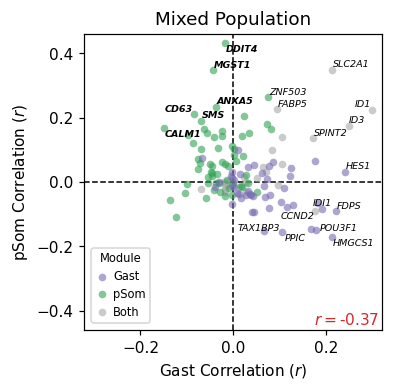

In [9]:
fig, ax = plt.subplots(1, 1, figsize = (3.5, 3.5))
for mod, sdf in R.groupby('Module', observed=True):
    sdf.plot(kind='scatter', x='Gast', y='pSom', color=c_dict[mod], label=mod, s=25, alpha=.6, linewidth=0, ax=ax)
ax.axvline(0, color='k', lw=1, ls='--', zorder=0); ax.axhline(0, color='k', lw=1, ls='--', zorder=0)
xl = abs(np.asarray(ax.get_xlim())).max(); yl = abs(np.asarray(ax.get_ylim())).max()
ax.set_xlim(-xl, xl); ax.set_ylim(-yl, yl)
texts = []
for i in R.head(20).index:
    xi, yi = R.loc[i].Gast, R.loc[i].pSom
    fw = 'bold' if (xi < 0 and yi > 0) else 'normal'
    texts.append(ax.text(xi, yi, i, fontsize=6.25, fontstyle='italic', fontweight=fw))
if adjust_text is not None: adjust_text(texts=texts)
ax.legend(title='Module', loc='lower left', title_fontsize=7.5, handlelength=1,
          handletextpad=.5, borderaxespad=.65, fontsize=7.5, reverse=True)
ax.text(.99, .01, r'$r=$' + f'{rval}', transform=ax.transAxes, fontsize=10, color='tab:red', ha='right', va='bottom')
ax.set_title('Mixed Population'); ax.set_xlabel(r'Gast Correlation ($r$)'); ax.set_ylabel(r'pSom Correlation ($r$)')
fig.savefig(os.path.join(pth_out, 'modules.pdf'), bbox_inches='tight')

### Gate 3 verdict
**GO.** The hub shows significant negative Gast<->pSom module cross-repression (competitive mutual exclusivity), the branching signature — magnitude comparable to the Puram (-0.49) / Filbin (-0.34) branching anchors and opposite in sign to non-branching datasets.